# Fuzzy Mamdani vs Sugeno untuk Kontrol AC Ruang Kelas Hemat Energi

Notebook pendamping artikel **"Perbandingan Fuzzy Mamdani dan Sugeno pada Kontrol Pendingin Ruangan Kelas Hemat Energi Berbasis Suhu, Kelembapan, dan Jumlah Penghuni"** (Tugas Kelompok Fuzzy Logic).

Isi notebook:

1. Perancangan sistem fuzzy: himpunan keanggotaan, 36 aturan, inferensi Mamdani dan Sugeno (ditulis dari nol dengan NumPy).
2. Perbandingan statis kedua metode pada seluruh ruang input.
3. Simulasi *closed-loop* satu hari sekolah (07.00-15.00) terhadap termostat on/off konvensional.
4. Analisis sensitivitas.
5. Penyimpanan semua tabel dan gambar ke folder `hasil/`.

> **Catatan:** simulasi dengan model termal sederhana dan parameter asumsi, bukan pengukuran lapangan. Angka penghematan berlaku untuk model ini dan tidak boleh dibaca sebagai hasil eksperimen pada AC sungguhan.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

OUT = Path("hasil")
(OUT / "gambar").mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#2b2a28", "axes.titlesize": 10,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})

# Warna per entitas (konsisten di semua gambar): biru, oranye, aqua + dua abu-abu untuk pembanding
WARNA = {"T22": "#a7a59d", "T24": "#2a78d6", "T26": "#c3c2b7", "Mamdani": "#eb6834", "Sugeno": "#1baf7a"}
RAMP_BIRU = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
CMAP_URUT = LinearSegmentedColormap.from_list("urut", RAMP_BIRU)
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#9ec5f4", "#f0efec", "#f3a58a", "#e34948"])

## 1. Perancangan sistem fuzzy

**Masalah:** mengatur kecepatan kompresor AC inverter di ruang kelas agar hemat energi tanpa keluar dari rentang nyaman termal.

| Peran | Variabel | Semesta | Himpunan fuzzy |
|---|---|---|---|
| Input 1 | Suhu ruang (°C) | 18-36 | Dingin, Nyaman, Hangat, Panas |
| Input 2 | Kelembapan relatif (%) | 30-100 | Rendah, Sedang, Tinggi |
| Input 3 | Jumlah penghuni (orang) | 0-40 | Sedikit, Sedang, Banyak |
| Output | Kecepatan kompresor (%) | 0-100 | SR, R, S, T, ST (sangat rendah ... sangat tinggi) |

Batas himpunan suhu dirancang mengikuti rentang temperatur efektif SNI 03-6572-2001 (nyaman optimal 22,8-25,8 °C, nyaman hangat 25,8-27,1 °C).

In [2]:
def trapmf(x, a, b, c, d):
    """Fungsi keanggotaan trapesium. a==b atau c==d menghasilkan bahu (shoulder)."""
    x = np.asarray(x, float)
    naik = np.where(x >= b, 1.0, np.where(x <= a, 0.0, (x - a) / (b - a + 1e-12)))
    turun = np.where(x <= c, 1.0, np.where(x >= d, 0.0, (d - x) / (d - c + 1e-12)))
    return np.minimum(naik, turun)


# Semesta pembicaraan
UNIV_T, UNIV_H, UNIV_O = (18.0, 36.0), (30.0, 100.0), (0.0, 40.0)

# Himpunan fuzzy: (a, b, c, d) trapesium; segitiga ditulis (a, b, b, c)
SUHU = {"Dingin": (18, 18, 21.5, 23.5), "Nyaman": (22.5, 23.8, 25.2, 26.5),
        "Hangat": (25.5, 27.5, 27.5, 29.5), "Panas": (28.5, 30.5, 36, 36)}
RH = {"Rendah": (30, 30, 40, 52), "Sedang": (45, 57.5, 57.5, 70), "Tinggi": (62, 75, 100, 100)}
ORANG = {"Sedikit": (0, 0, 5, 12), "Sedang": (8, 20, 20, 32), "Banyak": (26, 34, 40, 40)}
KOMP = {"SR": (0, 0, 5, 15), "R": (10, 25, 25, 40), "S": (35, 50, 50, 65),
        "T": (60, 75, 75, 90), "ST": (85, 95, 100, 100)}
NAMA_Y_PANJANG = {"SR": "Sangat rendah", "R": "Rendah", "S": "Sedang", "T": "Tinggi", "ST": "Sangat tinggi"}

### Basis aturan (36 aturan, seluruh kombinasi 4 × 3 × 3)

Logikanya dirancang dari penalaran beban termal, bukan ditebak per sel:

* Suhu menentukan **tingkat dasar**: Dingin → kompresor minimum; Nyaman → sedang; Hangat → tinggi; Panas → sangat tinggi.
* Kelembapan **tinggi** dan penghuni **banyak** menambah beban (geser +1 tingkat); kelembapan **rendah** dan penghuni **sedikit** mengurangi beban (geser −1 tingkat).
* Pergeseran dibatasi jendela per suhu: ruang Dingin tidak boleh didinginkan lagi, ruang Panas tidak boleh turun di bawah "Tinggi".

In [3]:
def tingkat_keluaran(t, h, o):
    """Indeks himpunan output (0=SR ... 4=ST) untuk indeks suhu t, RH h, penghuni o."""
    geser = (h - 1) + (o - 1)          # -2 .. +2
    if t == 0:                         # Dingin
        return 0
    if t == 1:                         # Nyaman
        return int(np.clip(2 + geser, 0, 3))
    if t == 2:                         # Hangat
        return int(np.clip(3 + geser, 2, 4))
    return int(np.clip(4 + geser, 3, 4))   # Panas


NAMA_T, NAMA_H, NAMA_O, NAMA_Y = list(SUHU), list(RH), list(ORANG), list(KOMP)
ATURAN = [(t, h, o, tingkat_keluaran(t, h, o))
          for t in range(len(NAMA_T)) for h in range(len(NAMA_H)) for o in range(len(NAMA_O))]
R_T, R_H, R_O, R_L = (np.array(k) for k in zip(*ATURAN))

df_aturan = pd.DataFrame({
    "No": np.arange(1, len(ATURAN) + 1),
    "Suhu": [NAMA_T[i] for i in R_T], "Kelembapan": [NAMA_H[i] for i in R_H],
    "Penghuni": [NAMA_O[i] for i in R_O], "Kecepatan kompresor": [NAMA_Y[i] for i in R_L],
})
print(f"Jumlah aturan: {len(df_aturan)}")
df_aturan

Jumlah aturan: 36


,No,Suhu,Kelembapan,Penghuni,Kecepatan kompresor
0,1,Dingin,Rendah,Sedikit,SR
1,2,Dingin,Rendah,Sedang,SR
2,3,Dingin,Rendah,Banyak,SR
3,4,Dingin,Sedang,Sedikit,SR
4,5,Dingin,Sedang,Sedang,SR
5,6,Dingin,Sedang,Banyak,SR
6,7,Dingin,Tinggi,Sedikit,SR
7,8,Dingin,Tinggi,Sedang,SR
8,9,Dingin,Tinggi,Banyak,SR
9,10,Nyaman,Rendah,Sedikit,SR


### Mesin inferensi (ditulis sendiri)

* **Mamdani:** operator AND = min, implikasi = min, agregasi = max, defuzzifikasi = centroid.
* **Sugeno orde-nol:** operator AND = product, konsekuen berupa konstanta (puncak tiap himpunan output: 5, 25, 50, 75, 95), defuzzifikasi = rata-rata terbobot.

Keduanya memakai fuzzifikasi dan basis aturan yang sama persis, sehingga perbedaan hasil murni berasal dari mekanisme inferensi.

In [4]:
Y_UNIV = np.linspace(0, 100, 401)
MU_Y = np.stack([trapmf(Y_UNIV, *p) for p in KOMP.values()])      # (5, 401)
Z_SUGENO = np.array([5.0, 25.0, 50.0, 75.0, 95.0])                # konsekuen konstan Sugeno


def fuzzifikasi(T, H, N):
    T, H, N = np.broadcast_arrays(*(np.atleast_1d(np.asarray(v, float)) for v in (T, H, N)))
    T, H, N = np.clip(T, *UNIV_T), np.clip(H, *UNIV_H), np.clip(N, *UNIV_O)
    mT = np.stack([trapmf(T, *p) for p in SUHU.values()], axis=1)
    mH = np.stack([trapmf(H, *p) for p in RH.values()], axis=1)
    mO = np.stack([trapmf(N, *p) for p in ORANG.values()], axis=1)
    return mT, mH, mO


def kekuatan_aturan(T, H, N, operator):
    mT, mH, mO = fuzzifikasi(T, H, N)
    a, b, c = mT[:, R_T], mH[:, R_H], mO[:, R_O]            # masing-masing (n, 36)
    return np.minimum(np.minimum(a, b), c) if operator == "min" else a * b * c


def mamdani(T, H, N):
    w = kekuatan_aturan(T, H, N, "min")
    alfa = np.stack([w[:, R_L == m].max(axis=1) for m in range(len(KOMP))], axis=1)   # (n, 5)
    agregat = np.max(np.minimum(alfa[:, :, None], MU_Y[None, :, :]), axis=1)           # (n, 401)
    luas = agregat.sum(axis=1)
    return (agregat * Y_UNIV).sum(axis=1) / np.where(luas > 0, luas, 1.0)


def sugeno(T, H, N):
    w = kekuatan_aturan(T, H, N, "prod")
    return (w * Z_SUGENO[R_L]).sum(axis=1) / w.sum(axis=1)


# Uji kelengkapan: tidak boleh ada titik input tanpa aturan yang menyala
Tg, Hg, Og = np.meshgrid(np.linspace(18, 36, 73), np.linspace(30, 100, 71), np.linspace(0, 40, 41), indexing="ij")
assert kekuatan_aturan(Tg.ravel(), Hg.ravel(), Og.ravel(), "prod").sum(axis=1).min() > 0
print("Cakupan basis aturan lengkap. Contoh: Mamdani =", mamdani(26, 70, 36).round(2), "| Sugeno =", sugeno(26, 70, 36).round(2))

Cakupan basis aturan lengkap. Contoh: Mamdani = [79.63] | Sugeno = [82.88]


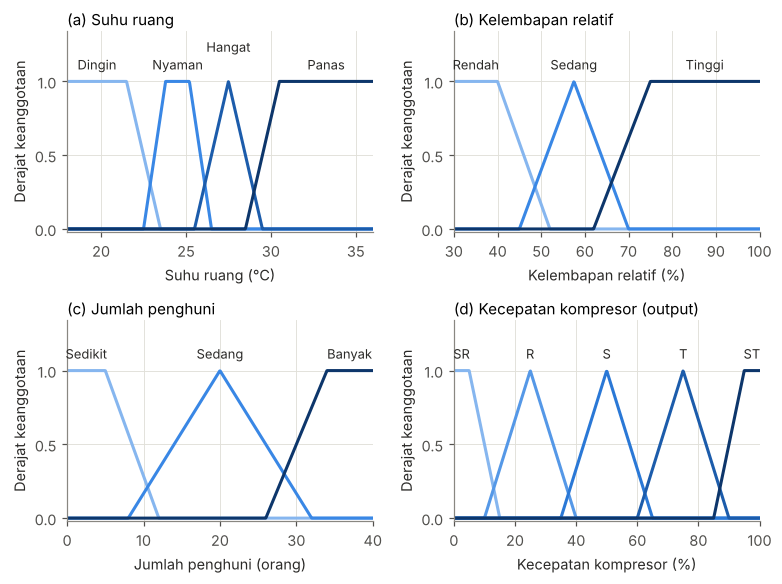

In [5]:
def gambar_himpunan():
    fig, axs = plt.subplots(2, 2, figsize=(7.2, 5.4))
    spek = [
        (axs[0, 0], SUHU, UNIV_T, "Suhu ruang (°C)", "(a) Suhu ruang"),
        (axs[0, 1], RH, UNIV_H, "Kelembapan relatif (%)", "(b) Kelembapan relatif"),
        (axs[1, 0], ORANG, UNIV_O, "Jumlah penghuni (orang)", "(c) Jumlah penghuni"),
        (axs[1, 1], KOMP, (0, 100), "Kecepatan kompresor (%)", "(d) Kecepatan kompresor (output)"),
    ]
    for ax, himp, (lo, hi), xlabel, judul in spek:
        x = np.linspace(lo, hi, 600)
        warna = [RAMP_BIRU[i] for i in np.linspace(1, 4, len(himp)).round().astype(int)] if len(himp) <= 4 else \
                ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
        for (nama, p), c in zip(himp.items(), warna):
            y = trapmf(x, *p)
            ax.plot(x, y, color=c, lw=2.0)
            puncak = x[y >= y.max() - 0.01].mean()
            ax.text(puncak, 1.06 + (0.12 if nama == "Hangat" else 0.0), nama, ha="center", va="bottom", fontsize=8.5, color="#2b2a28")
        ax.set_xlabel(xlabel); ax.set_ylabel("Derajat keanggotaan")
        ax.set_ylim(-0.02, 1.34); ax.set_yticks([0, 0.5, 1]); ax.set_xlim(lo, hi)
        ax.set_title(judul, loc="left", pad=4)
    fig.tight_layout()
    fig.savefig(OUT / "gambar" / "fig1_himpunan_fuzzy.png", bbox_inches="tight")
    return fig

gambar_himpunan();

## 2. Perbandingan statis Mamdani vs Sugeno

Sebelum dipasang ke ruangan, kedua metode dievaluasi pada grid input rapat (suhu 20-34 °C tiap 0,25; RH 40-95 % tiap 2,5; penghuni 0-40 tiap 2) dan pada delapan kasus uji representatif.

In [6]:
def per_potongan(f, T, H, N, ukuran=2000):
    return np.concatenate([f(T[i:i + ukuran], H[i:i + ukuran], N[i:i + ukuran]) for i in range(0, T.size, ukuran)])

Tt, Hh, Oo = np.meshgrid(np.arange(20, 34.01, 0.25), np.arange(40, 95.01, 2.5), np.arange(0, 40.01, 2), indexing="ij")
yM = per_potongan(mamdani, Tt.ravel(), Hh.ravel(), Oo.ravel())
yS = per_potongan(sugeno, Tt.ravel(), Hh.ravel(), Oo.ravel())
selisih = yM - yS
statik = {
    "n_titik": int(selisih.size),
    "MAE": float(np.abs(selisih).mean()), "RMSE": float(np.sqrt((selisih ** 2).mean())),
    "selisih_maks": float(np.abs(selisih).max()), "korelasi": float(np.corrcoef(yM, yS)[0, 1]),
    "rata_Mamdani": float(yM.mean()), "rata_Sugeno": float(yS.mean()),
}
print({k: round(v, 3) if isinstance(v, float) else v for k, v in statik.items()})

kasus = [("K1", 23.5, 55, 8), ("K2", 24.5, 45, 3), ("K3", 25.0, 60, 20), ("K4", 26.0, 70, 36),
         ("K5", 27.5, 65, 30), ("K6", 28.0, 50, 12), ("K7", 29.0, 75, 38), ("K8", 31.0, 80, 40)]
df_kasus = pd.DataFrame(kasus, columns=["Kasus", "Suhu (°C)", "RH (%)", "Penghuni"])
df_kasus["Mamdani (%)"] = [float(mamdani(t, h, o)[0]) for _, t, h, o in kasus]
df_kasus["Sugeno (%)"] = [float(sugeno(t, h, o)[0]) for _, t, h, o in kasus]
df_kasus["Selisih"] = df_kasus["Mamdani (%)"] - df_kasus["Sugeno (%)"]
df_kasus.round(2)

{'n_titik': 27531, 'MAE': 1.469, 'RMSE': 2.656, 'selisih_maks': 22.539, 'korelasi': 0.998, 'rata_Mamdani': 62.292, 'rata_Sugeno': 62.423}


,Kasus,Suhu (°C),RH (%),Penghuni,Mamdani (%),Sugeno (%),Selisih
0,K1,23.5,55,8,25.00,25.00,0.00
1,K2,24.5,45,3,6.09,5.00,1.09
2,K3,25.0,60,20,50.00,50.00,-0.00
3,K4,26.0,70,36,79.63,82.88,-3.25
4,K5,27.5,65,30,84.76,91.83,-7.07
5,K6,28.0,50,12,66.25,67.65,-1.40
6,K7,29.0,75,38,93.17,95.00,-1.83
7,K8,31.0,80,40,94.65,95.00,-0.35


Mamdani 158 µs | Sugeno 127 µs | rasio 1.2x


Selisih maksimum pada RH=65 %: 24.53 poin persen


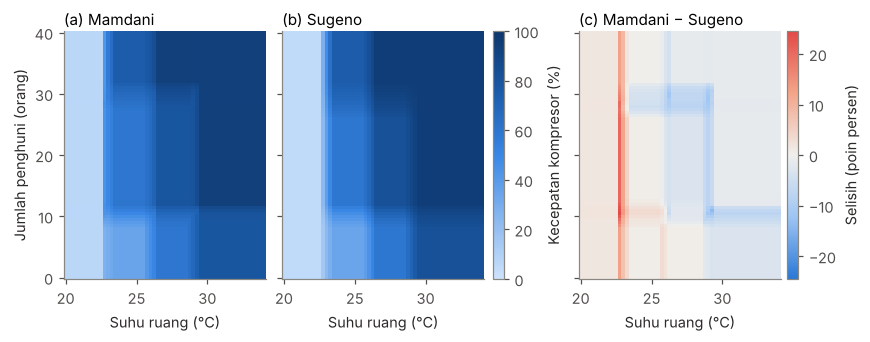

In [7]:
# Waktu komputasi relatif per satu inferensi (bergantung mesin; yang bermakna adalah rasionya)
def waktu_per_inferensi(f, n=1500):
    t0 = time.perf_counter()
    for i in range(n):
        f(24 + (i % 10), 55 + (i % 30), i % 40)
    return (time.perf_counter() - t0) / n * 1e6

t_mamdani, t_sugeno = waktu_per_inferensi(mamdani), waktu_per_inferensi(sugeno)
statik.update({"us_Mamdani": t_mamdani, "us_Sugeno": t_sugeno, "rasio_waktu": t_mamdani / t_sugeno})
print(f"Mamdani {t_mamdani:.0f} µs | Sugeno {t_sugeno:.0f} µs | rasio {t_mamdani / t_sugeno:.1f}x")

# Permukaan kontrol pada RH = 65 %
Tp, Op = np.meshgrid(np.arange(20, 34.01, 0.25), np.arange(0, 40.01, 0.5))
zM = mamdani(Tp.ravel(), np.full(Tp.size, 65.0), Op.ravel()).reshape(Tp.shape)
zS = sugeno(Tp.ravel(), np.full(Tp.size, 65.0), Op.ravel()).reshape(Tp.shape)

fig, axs = plt.subplots(1, 3, figsize=(7.8, 3.0), sharey=True, layout="constrained")
for ax, z, jud in ((axs[0], zM, "(a) Mamdani"), (axs[1], zS, "(b) Sugeno")):
    m = ax.pcolormesh(Tp, Op, z, cmap=CMAP_URUT, vmin=0, vmax=100, shading="auto", rasterized=True)
    ax.set_title(jud, loc="left", pad=4); ax.set_xlabel("Suhu ruang (°C)"); ax.grid(False)
cb = fig.colorbar(m, ax=axs[:2], aspect=22, pad=0.02); cb.set_label("Kecepatan kompresor (%)")
lim = float(np.abs(zM - zS).max())
m2 = axs[2].pcolormesh(Tp, Op, zM - zS, cmap=CMAP_DIV, vmin=-lim, vmax=lim, shading="auto", rasterized=True)
axs[2].set_title("(c) Mamdani − Sugeno", loc="left", pad=4); axs[2].set_xlabel("Suhu ruang (°C)"); axs[2].grid(False)
cb2 = fig.colorbar(m2, ax=axs[2], aspect=22, pad=0.03); cb2.set_label("Selisih (poin persen)")
axs[0].set_ylabel("Jumlah penghuni (orang)")
for c in (cb, cb2):
    c.ax.grid(False)
fig.savefig(OUT / "gambar" / "fig2_permukaan_kontrol.png", bbox_inches="tight")
statik["selisih_maks_RH65"] = lim
print("Selisih maksimum pada RH=65 %:", round(lim, 2), "poin persen")

## 3. Model ruang kelas dan simulasi *closed-loop*

Satu zona terpadu (suhu dan rasio kelembapan) dengan neraca energi dan neraca uap air:

* Neraca energi: C·dT/dt = UA·(T_luar − T) + N·Q_orang + Q_alat + Q_surya(t) − s·Q_maks
* Neraca uap air: M·dw/dt = ṁ_infiltrasi·(w_luar − w) + N·ṁ_orang − s·ṁ_AC·ε·max(0, w − w_koil)
* Daya listrik: P(s) = P_dasar + P_komp·s^k (k > 1 mewakili efisiensi beban parsial pada kompresor inverter)

Kelas 8 × 7 × 3 m (168 m³), kapasitas 40 orang, satu hari sekolah 07.00-15.00 dengan jam istirahat. Suhu awal 29,5 °C dan RH 75 % (ruang tertutup semalaman).

In [8]:
PLANT = dict(
    C=2.5e6,            # J/K    kapasitas termal efektif (udara + perabot + permukaan dalam)
    UA=120.0,           # W/K    konduktansi selubung bangunan
    Q_orang=75.0,       # W      kalor sensibel per orang
    Q_alat=500.0,       # W      lampu + proyektor/laptop
    Q_surya_maks=500.0, # W      puncak beban surya lewat jendela
    Q_maks=6000.0,      # W      kapasitas pendinginan maksimum
    V=168.0, ACH=1.0,   # m3, pertukaran udara per jam (infiltrasi/ventilasi)
    faktor_lembap=4.0,  # kali massa udara: penyangga uap air oleh perabot, buku, dan dinding
    m_uap_orang=1.85e-5,# kg/s   uap air per orang (~45 W laten)
    m_udara_AC=0.6,     # kg/s   debit udara unit indoor
    eps_dehum=0.7,      # efektivitas koil terhadap penurunan rasio kelembapan
    T_koil=12.0,        # °C     suhu permukaan koil
    P_dasar=150.0, P_komp=1800.0, eksp=1.3, P_off=30.0,   # W
    s_min=0.15, ambang_mati=0.08,   # kecepatan minimum kompresor inverter & ambang mati
)
RHO = 1.2           # kg/m3
P_ATM = 1013.25     # hPa


def p_jenuh(T):                      # Magnus, hPa
    return 6.112 * np.exp(17.62 * T / (243.12 + T))

def w_dari_rh(T, rh):                # rasio kelembapan kg/kg
    e = rh / 100.0 * p_jenuh(T)
    return 0.622 * e / (P_ATM - e)

def rh_dari_w(T, w):
    e = w * P_ATM / (0.622 + w)
    return float(np.clip(100.0 * e / p_jenuh(T), 0.0, 100.0))


def suhu_luar(jam):  return 30.0 + 3.5 * np.cos(2 * np.pi * (jam - 14.0) / 24.0)
def rh_luar(Tl):     return float(np.clip(80.0 - 4.0 * (Tl - 29.0), 45.0, 95.0))
def surya(jam, pl):  return pl["Q_surya_maks"] * max(0.0, np.sin(np.pi * (jam - 6.0) / 12.0))

_JAM = [7.0, 7.25, 9.5, 9.58, 10.0, 10.08, 12.0, 12.08, 13.0, 13.08, 15.0]
_ORG = [0, 36, 36, 8, 8, 36, 36, 5, 5, 32, 32]
def penghuni(jam):   return float(np.interp(jam, _JAM, _ORG))

def daya_listrik(s, pl):
    return pl["P_off"] if s <= 0 else pl["P_dasar"] + pl["P_komp"] * s ** pl["eksp"]

In [9]:
class TermostatOnOff:
    """Kompresor kecepatan tetap: nyala penuh saat T >= sp+h, mati saat T <= sp-h, dengan proteksi 3 menit."""
    def __init__(self, setpoint, histeresis=1.0, min_nyala=180.0, min_mati=180.0):
        self.sp, self.h, self.min_on, self.min_off = setpoint, histeresis, min_nyala, min_mati
        self.nyala, self.t_ganti = False, -1e9

    def langkah(self, t, T, RH, N):
        if self.nyala and T <= self.sp - self.h and t - self.t_ganti >= self.min_on:
            self.nyala, self.t_ganti = False, t
        elif (not self.nyala) and T >= self.sp + self.h and t - self.t_ganti >= self.min_off:
            self.nyala, self.t_ganti = True, t
        return 1.0 if self.nyala else 0.0


class KontrolFuzzy:
    """Pengendali fuzzy diskret: inferensi tiap `periode` detik, keluaran ditahan di antara sampel."""
    def __init__(self, metode, pl, periode=30.0):
        self.f = {"mamdani": mamdani, "sugeno": sugeno}[metode]
        self.pl, self.periode = pl, periode
        self.t_terakhir, self.y = -1e9, 0.0

    def langkah(self, t, T, RH, N):
        if t - self.t_terakhir >= self.periode:
            self.y, self.t_terakhir = float(self.f(T, RH, N)[0]), t
        u = self.y / 100.0
        return 0.0 if u < self.pl["ambang_mati"] else float(np.clip(u, self.pl["s_min"], 1.0))


SKENARIO_DASAR = dict(dT_luar=0.0, skala_orang=1.0)


def jalankan(ctrl, pl=PLANT, skenario=SKENARIO_DASAR, dt=10.0, durasi_jam=8.0, jam0=7.0, T0=29.5, RH0=75.0):
    n = int(durasi_jam * 3600 / dt)
    T, w = T0, w_dari_rh(T0, RH0)
    M = RHO * pl["V"] * pl["faktor_lembap"]
    m_inf = RHO * pl["V"] * pl["ACH"] / 3600.0
    w_koil = w_dari_rh(pl["T_koil"], 100.0)
    energi_kwh, mulai, s_prev = 0.0, 0, 0.0
    rec = {k: [] for k in ("jam", "T", "RH", "N", "s", "P", "Tluar")}
    for i in range(n):
        t, jam = i * dt, jam0 + i * dt / 3600.0
        Tl = suhu_luar(jam) + skenario["dT_luar"]
        wl = w_dari_rh(Tl, rh_luar(Tl))
        N = int(round(penghuni(jam) * skenario["skala_orang"]))
        RH = rh_dari_w(T, w)
        s = ctrl.langkah(t, T, RH, N)
        P = daya_listrik(s, pl)
        energi_kwh += P * dt / 3.6e6
        if s > 0 and s_prev == 0:
            mulai += 1
        s_prev = s
        if i % int(60 / dt) == 0:
            for k, v in zip(rec, (jam, T, RH, N, s, P, Tl)):
                rec[k].append(v)
        Q_masuk = pl["UA"] * (Tl - T) + N * pl["Q_orang"] + pl["Q_alat"] + surya(jam, pl)
        T += dt / pl["C"] * (Q_masuk - s * pl["Q_maks"])
        m_dehum = s * pl["m_udara_AC"] * pl["eps_dehum"] * max(0.0, w - w_koil)
        w += dt / M * (m_inf * (wl - w) + N * pl["m_uap_orang"] - m_dehum)
    seri = pd.DataFrame(rec)
    return energi_kwh, mulai, seri


def metrik(energi, mulai, seri):
    ok = seri["N"] >= 5                       # menit berpenghuni
    T, RH = seri.loc[ok, "T"], seri.loc[ok, "RH"]
    return {
        "Energi (kWh)": energi,
        "Suhu rata-rata (°C)": T.mean(), "Suhu maks (°C)": T.max(),
        "Waktu nyaman (%)": 100 * ((T >= 22.8) & (T <= 27.1)).mean(),
        "Waktu terlalu panas (%)": 100 * (T > 27.1).mean(),
        "Waktu terlalu dingin (%)": 100 * (T < 22.8).mean(),
        "Nyaman setelah 08.00 (%)": 100 * ((seri.loc[ok & (seri["jam"] >= 8), "T"] >= 22.8) & (seri.loc[ok & (seri["jam"] >= 8), "T"] <= 27.1)).mean(),
        "Pendinginan awal ke 27,1 °C (menit)": 60 * (seri.loc[seri["T"] <= 27.1, "jam"].min() - seri["jam"].iloc[0]),
        "RH rata-rata (%)": RH.mean(), "Waktu RH > 70% (%)": 100 * (RH > 70).mean(),
        "Start kompresor": mulai,
    }

In [10]:
def pabrik(nama, pl=PLANT):
    return {
        "T22": lambda: TermostatOnOff(22.0), "T24": lambda: TermostatOnOff(24.0), "T26": lambda: TermostatOnOff(26.0),
        "Mamdani": lambda: KontrolFuzzy("mamdani", pl), "Sugeno": lambda: KontrolFuzzy("sugeno", pl),
    }[nama]()

LABEL = {"T22": "Termostat 22 °C", "T24": "Termostat 24 °C (acuan)", "T26": "Termostat 26 °C",
         "Mamdani": "Fuzzy Mamdani", "Sugeno": "Fuzzy Sugeno"}

utama, seri_utama = {}, {}
for k in LABEL:
    e, st, sr = jalankan(pabrik(k))
    utama[k], seri_utama[k] = metrik(e, st, sr), sr

df_utama = pd.DataFrame(utama).T
df_utama.insert(1, "Hemat vs T24 (%)", 100 * (1 - df_utama["Energi (kWh)"] / df_utama.loc["T24", "Energi (kWh)"]))
df_utama.index = [LABEL[k] for k in df_utama.index]
df_utama.round(2)

,Energi (kWh),Hemat vs T24 (%),Suhu rata-rata (°C),Suhu maks (°C),Waktu nyaman (%),Waktu terlalu panas (%),Waktu terlalu dingin (%),Nyaman setelah 08.00 (%),"Pendinginan awal ke 27,1 °C (menit)",RH rata-rata (%),Waktu RH > 70% (%),Start kompresor
Termostat 22 °C,12.71,-10.84,22.95,29.25,27.20,6.28,66.53,24.29,32.0,69.70,69.67,5.0
Termostat 24 °C (acuan),11.47,0.00,24.42,29.25,93.72,6.28,0.00,100.00,32.0,64.78,1.46,6.0
Termostat 26 °C,10.52,8.28,26.12,29.25,93.72,6.28,0.00,100.00,32.0,59.90,1.46,7.0
Fuzzy Mamdani,10.34,9.85,25.85,29.28,92.05,7.95,0.00,100.00,40.0,60.49,1.67,1.0
Fuzzy Sugeno,10.37,9.52,25.79,29.27,92.47,7.53,0.00,100.00,38.0,60.65,1.46,1.0


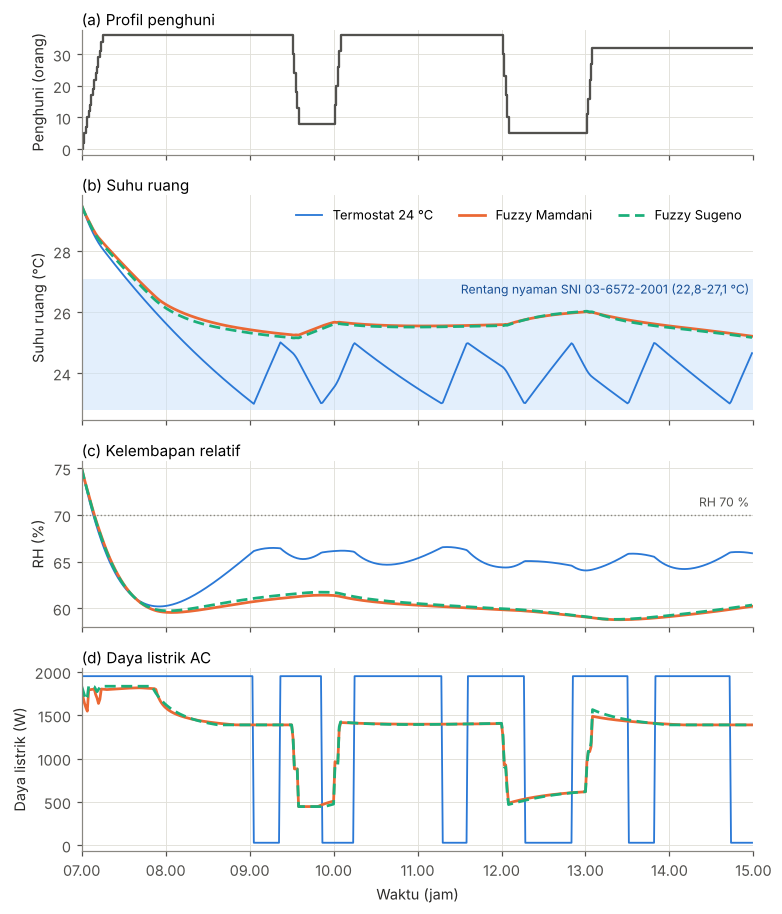

In [11]:
JAM_TICK = np.arange(7, 16)
def label_jam(ax):
    ax.set_xticks(JAM_TICK); ax.set_xticklabels([f"{h:02d}.00" for h in JAM_TICK]); ax.set_xlim(7, 15)

def gambar_simulasi():
    fig, ax = plt.subplots(4, 1, figsize=(7.2, 8.4), sharex=True, gridspec_kw={"height_ratios": [0.75, 1.35, 1.0, 1.1]})
    gaya = {"T24": dict(color=WARNA["T24"], lw=1.2, ls="-"), "Mamdani": dict(color=WARNA["Mamdani"], lw=1.8, ls="-"),
            "Sugeno": dict(color=WARNA["Sugeno"], lw=1.8, ls=(0, (4, 2)))}
    s0 = seri_utama["T24"]
    ax[0].step(s0["jam"], s0["N"], where="post", color="#52514e", lw=1.5)
    ax[0].set_ylabel("Penghuni (orang)"); ax[0].set_title("(a) Profil penghuni", loc="left", pad=3)
    ax[1].axhspan(22.8, 27.1, color="#cde2fb", alpha=0.55, lw=0)
    ax[1].text(14.95, 27.0, "Rentang nyaman SNI 03-6572-2001 (22,8-27,1 °C)", ha="right", va="top", fontsize=8, color="#184f95")
    for k in ("T24", "Mamdani", "Sugeno"):
        ax[1].plot(seri_utama[k]["jam"], seri_utama[k]["T"], label=LABEL[k].replace(" (acuan)", ""), **gaya[k])
        ax[2].plot(seri_utama[k]["jam"], seri_utama[k]["RH"], **gaya[k])
        ax[3].plot(seri_utama[k]["jam"], seri_utama[k]["P"], **gaya[k])
    ax[1].set_ylabel("Suhu ruang (°C)"); ax[1].set_title("(b) Suhu ruang", loc="left", pad=3)
    ax[1].legend(loc="upper right", ncol=3, fontsize=8.5, bbox_to_anchor=(1.0, 1.0))
    ax[2].axhline(70, color="#898781", lw=0.9, ls=":")
    ax[2].text(14.95, 70.6, "RH 70 %", ha="right", va="bottom", fontsize=8, color="#52514e")
    ax[2].set_ylabel("RH (%)"); ax[2].set_title("(c) Kelembapan relatif", loc="left", pad=3)
    ax[3].set_ylabel("Daya listrik (W)"); ax[3].set_title("(d) Daya listrik AC", loc="left", pad=3)
    label_jam(ax[3]); ax[3].set_xlabel("Waktu (jam)")
    fig.tight_layout()
    fig.savefig(OUT / "gambar" / "fig3_simulasi_harian.png", bbox_inches="tight")
    return fig

gambar_simulasi();

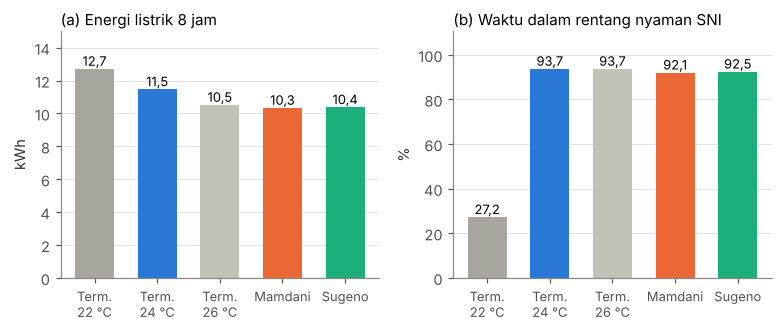

In [12]:
def gambar_batang():
    urutan = ["T22", "T24", "T26", "Mamdani", "Sugeno"]
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.1))
    for ax, kolom, judul, satuan in ((axs[0], "Energi (kWh)", "(a) Energi listrik 8 jam", "kWh"),
                                     (axs[1], "Waktu nyaman (%)", "(b) Waktu dalam rentang nyaman SNI", "%")):
        nilai = [df_utama.loc[LABEL[k], kolom] for k in urutan]
        bars = ax.bar(range(5), nilai, color=[WARNA[k] for k in urutan], width=0.62)
        for b, v in zip(bars, nilai):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}".replace(".", ","), ha="center", va="bottom", fontsize=8.5)
        ax.set_xticks(range(5)); ax.set_xticklabels(["Term.\n22 °C", "Term.\n24 °C", "Term.\n26 °C", "Mamdani", "Sugeno"], fontsize=8.5)
        ax.set_title(judul, loc="left", pad=4); ax.set_ylabel(satuan); ax.grid(axis="x", visible=False)
        ax.set_ylim(0, max(nilai) * 1.18)
    fig.tight_layout()
    fig.savefig(OUT / "gambar" / "fig4_energi_kenyamanan.png", bbox_inches="tight")
    return fig

gambar_batang();

## 4. Analisis sensitivitas

Apakah kesimpulan bertahan jika kondisi berubah? Diuji: hari lebih panas (+2 °C), kelas kecil (±14 orang), dan bentuk kurva daya kompresor (eksponen k = 1,0 / 1,3 / 1,6).

In [13]:
KONFIG = [
    ("Dasar (k = 1,3)", dict(), {}),
    ("Hari lebih panas (+2 °C)", dict(dT_luar=2.0), {}),
    ("Kelas kecil (±14 orang)", dict(skala_orang=0.4), {}),
    ("Daya linear (k = 1,0)", dict(), dict(eksp=1.0)),
    ("Daya sangat nonlinear (k = 1,6)", dict(), dict(eksp=1.6)),
    ("Penyangga lembap 1× (hanya udara)", dict(), dict(faktor_lembap=1.0)),
]
baris = []
for nama, sk, ubah_pl in KONFIG:
    pl = {**PLANT, **ubah_pl}
    skenario = {**SKENARIO_DASAR, **sk}
    hasil = {}
    for k in ("T24", "T26", "Mamdani", "Sugeno"):
        e, st, sr = jalankan(pabrik(k, pl), pl=pl, skenario=skenario)
        hasil[k] = metrik(e, st, sr)
    baris.append({
        "Skenario": nama,
        "E T24": hasil["T24"]["Energi (kWh)"], "E T26": hasil["T26"]["Energi (kWh)"],
        "E Mamdani": hasil["Mamdani"]["Energi (kWh)"], "E Sugeno": hasil["Sugeno"]["Energi (kWh)"],
        "Hemat Mamdani vs T24 (%)": 100 * (1 - hasil["Mamdani"]["Energi (kWh)"] / hasil["T24"]["Energi (kWh)"]),
        "Hemat Sugeno vs T24 (%)": 100 * (1 - hasil["Sugeno"]["Energi (kWh)"] / hasil["T24"]["Energi (kWh)"]),
        "Nyaman T24 (%)": hasil["T24"]["Waktu nyaman (%)"], "Nyaman T26 (%)": hasil["T26"]["Waktu nyaman (%)"],
        "Nyaman Mamdani (%)": hasil["Mamdani"]["Waktu nyaman (%)"], "Nyaman Sugeno (%)": hasil["Sugeno"]["Waktu nyaman (%)"],
        "RH>70 T24 (%)": hasil["T24"]["Waktu RH > 70% (%)"], "RH>70 T26 (%)": hasil["T26"]["Waktu RH > 70% (%)"],
        "RH>70 Mamdani (%)": hasil["Mamdani"]["Waktu RH > 70% (%)"], "RH>70 Sugeno (%)": hasil["Sugeno"]["Waktu RH > 70% (%)"],
        "Hemat Mamdani vs T26 (%)": 100 * (1 - hasil["Mamdani"]["Energi (kWh)"] / hasil["T26"]["Energi (kWh)"]),
        "Hemat Sugeno vs T26 (%)": 100 * (1 - hasil["Sugeno"]["Energi (kWh)"] / hasil["T26"]["Energi (kWh)"]),
    })
df_sens = pd.DataFrame(baris)
df_sens.round(2)

,Skenario,E T24,E T26,E Mamdani,E Sugeno,Hemat Mamdani vs T24 (%),Hemat Sugeno vs T24 (%),Nyaman T24 (%),Nyaman T26 (%),Nyaman Mamdani (%),Nyaman Sugeno (%),RH>70 T24 (%),RH>70 T26 (%),RH>70 Mamdani (%),RH>70 Sugeno (%),Hemat Mamdani vs T26 (%),Hemat Sugeno vs T26 (%)
0,"Dasar (k = 1,3)",11.47,10.52,10.34,10.37,9.85,9.52,93.72,93.72,92.05,92.47,1.46,1.46,1.67,1.46,1.71,1.35
1,Hari lebih panas (+2 °C),12.13,11.10,10.79,10.86,11.06,10.50,92.89,92.89,91.00,91.42,1.26,1.26,1.46,1.46,2.81,2.21
2,Kelas kecil (±14 orang),8.30,7.18,7.73,7.66,6.87,7.75,95.40,95.40,93.35,93.86,1.02,1.02,1.53,1.28,-7.73,-6.71
3,"Daya linear (k = 1,0)",11.47,10.52,11.22,11.25,2.14,1.92,93.72,93.72,92.05,92.47,1.46,1.46,1.67,1.46,-6.70,-6.94
4,"Daya sangat nonlinear (k = 1,6)",11.47,10.52,9.57,9.62,16.51,16.07,93.72,93.72,92.05,92.47,1.46,1.46,1.67,1.46,8.97,8.50
5,Penyangga lembap 1× (hanya udara),11.47,10.52,10.31,10.35,10.05,9.70,93.72,93.72,90.59,91.42,24.06,14.44,0.00,0.00,1.93,1.55


## 5. Menyimpan hasil

Semua angka yang dikutip di artikel diambil dari berkas di folder `hasil/` (CSV + JSON) sehingga bisa ditelusuri ke kode ini.

In [14]:
df_aturan.to_csv(OUT / "tabel_aturan.csv", index=False)
df_kasus.round(3).to_csv(OUT / "tabel_kasus_uji.csv", index=False)
df_utama.round(3).to_csv(OUT / "tabel_simulasi_utama.csv")
df_sens.round(3).to_csv(OUT / "tabel_sensitivitas.csv", index=False)
for k, sr in seri_utama.items():
    sr.round(3).to_csv(OUT / f"seri_waktu_{k}.csv", index=False)

ringkas = {
    "statik": statik,
    "utama": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in df_utama.reset_index(drop=True).assign(
        kunci=list(LABEL)).set_index("kunci").to_dict("index").items()},
    "sensitivitas": df_sens.round(4).to_dict("records"),
    "kasus": df_kasus.round(3).to_dict("records"),
}
(OUT / "ringkasan.json").write_text(json.dumps(ringkas, indent=2, ensure_ascii=False))
print("Tersimpan:", sorted(p.name for p in OUT.iterdir()))

Tersimpan: ['gambar', 'ringkasan.json', 'seri_waktu_Mamdani.csv', 'seri_waktu_Sugeno.csv', 'seri_waktu_T22.csv', 'seri_waktu_T24.csv', 'seri_waktu_T26.csv', 'tabel_aturan.csv', 'tabel_kasus_uji.csv', 'tabel_sensitivitas.csv', 'tabel_simulasi_utama.csv']


## 6. Kesimpulan

* **Energi** dibandingkan terhadap termostat 24 °C sebagai acuan. Termostat 22 °C dan 26 °C dimasukkan agar jelas apakah penghematan fuzzy hanya "efek menaikkan setpoint".
* **Waktu nyaman** dihitung hanya pada menit berpenghuni (≥ 5 orang) terhadap rentang 22,8-27,1 °C. Fase penurunan suhu awal (suhu ruang 29,5 °C) ikut terhitung untuk semua pengendali.
* Kelembapan memakai ambang 70 % sebagai batas kerja yang ditetapkan peneliti (bukan angka standar).
* Keterbatasan: satu zona terpadu, tanpa derau sensor, tanpa dinamika inrush kompresor, dan parameter ruang berupa asumsi. Validasi pada AC dan ruang nyata dibutuhkan sebelum klaim penghematan absolut.